# Logistic Regression

## Introduction

**Logistic Regression** is a supervised machine learning algorithm used for classification. It estimates the probability that an observation belongs to a particular class using a logistic (sigmoid) function.

Examples include predicting whether a tumour is benign or malignant, whether a customer will churn, and whether an email is spam.

## How Logistic Regression Works

1. **Input features:** The model receives independent variables (X) and a categorical target variable (y).
2. **Find relationships:** It learns how the input features relate to the probability of belonging to a class.
3. **Calculate probabilities:** It computes a weighted sum of the input features and applies the sigmoid function to produce probabilities between 0 and 1.
4. **Make predictions:** It applies a decision threshold, commonly 0.5, to assign observations to classes.
5. **Evaluate performance:** Predictions are compared with actual labels using classification metrics.

Logistic Regression commonly uses **Maximum Likelihood Estimation (MLE)** to estimate coefficients by finding values that make the observed class labels most likely.

## Mathematical Representation

### Linear Combination

$$
z = \beta_0 + \beta_1x_1 + \beta_2x_2 + \cdots + \beta_nx_n
$$

### Logistic (Sigmoid) Function

$$
P(Y=1|X) = \frac{1}{1+e^{-z}}
$$

Where:
- $P(Y=1|X)$: Probability of belonging to class 1.
- $z$: Linear combination of input features.
- $\beta_0$: Intercept.
- $\beta_1, \ldots, \beta_n$: Feature coefficients.
- $x_1, \ldots, x_n$: Input features.
- $e$: Euler's number.

## Key Points

- **Supervised learning:** Requires labelled training data.
- **Classification:** Predicts categorical outcomes.
- **Sigmoid function:** Converts the linear combination into a probability between 0 and 1.
- **Decision threshold:** Converts predicted probabilities into class labels.
- **MLE:** Estimates model coefficients by maximising the likelihood of observed outcomes.

## Advantages and Limitations

**Advantages:** Simple, interpretable, computationally efficient, and provides probability estimates.

**Limitations:** Assumes a linear relationship between predictors and the log-odds of the outcome, struggles with complex nonlinear relationships, and can be affected by multicollinearity and class imbalance.

In [1]:
# imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report,roc_auc_score,roc_curve)

# Breast cancer 

In [6]:
# load dataset
cancer = load_breast_cancer()

# Convert features into a DataFrame
df = pd.DataFrame(cancer.data, columns=cancer.feature_names)

# Add target column
df['target'] = cancer.target
print(df.shape)
df.head()

(569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [7]:
# information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [8]:
# summary stats
df.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


In [11]:
# missing values
df.isnull().sum()

mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
dtype: int64

In [9]:
df['target'].value_counts()

target
1    357
0    212
Name: count, dtype: int64

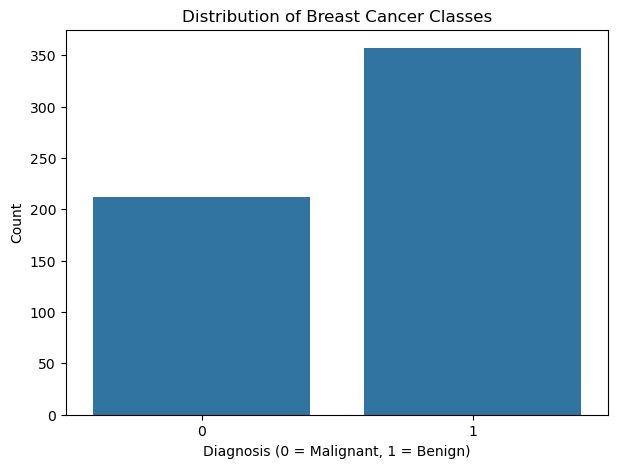

In [10]:
# target distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='target')
plt.title('Distribution of Breast Cancer Classes')
plt.xlabel('Diagnosis (0 = Malignant, 1 = Benign)')
plt.ylabel('Count')
plt.show()

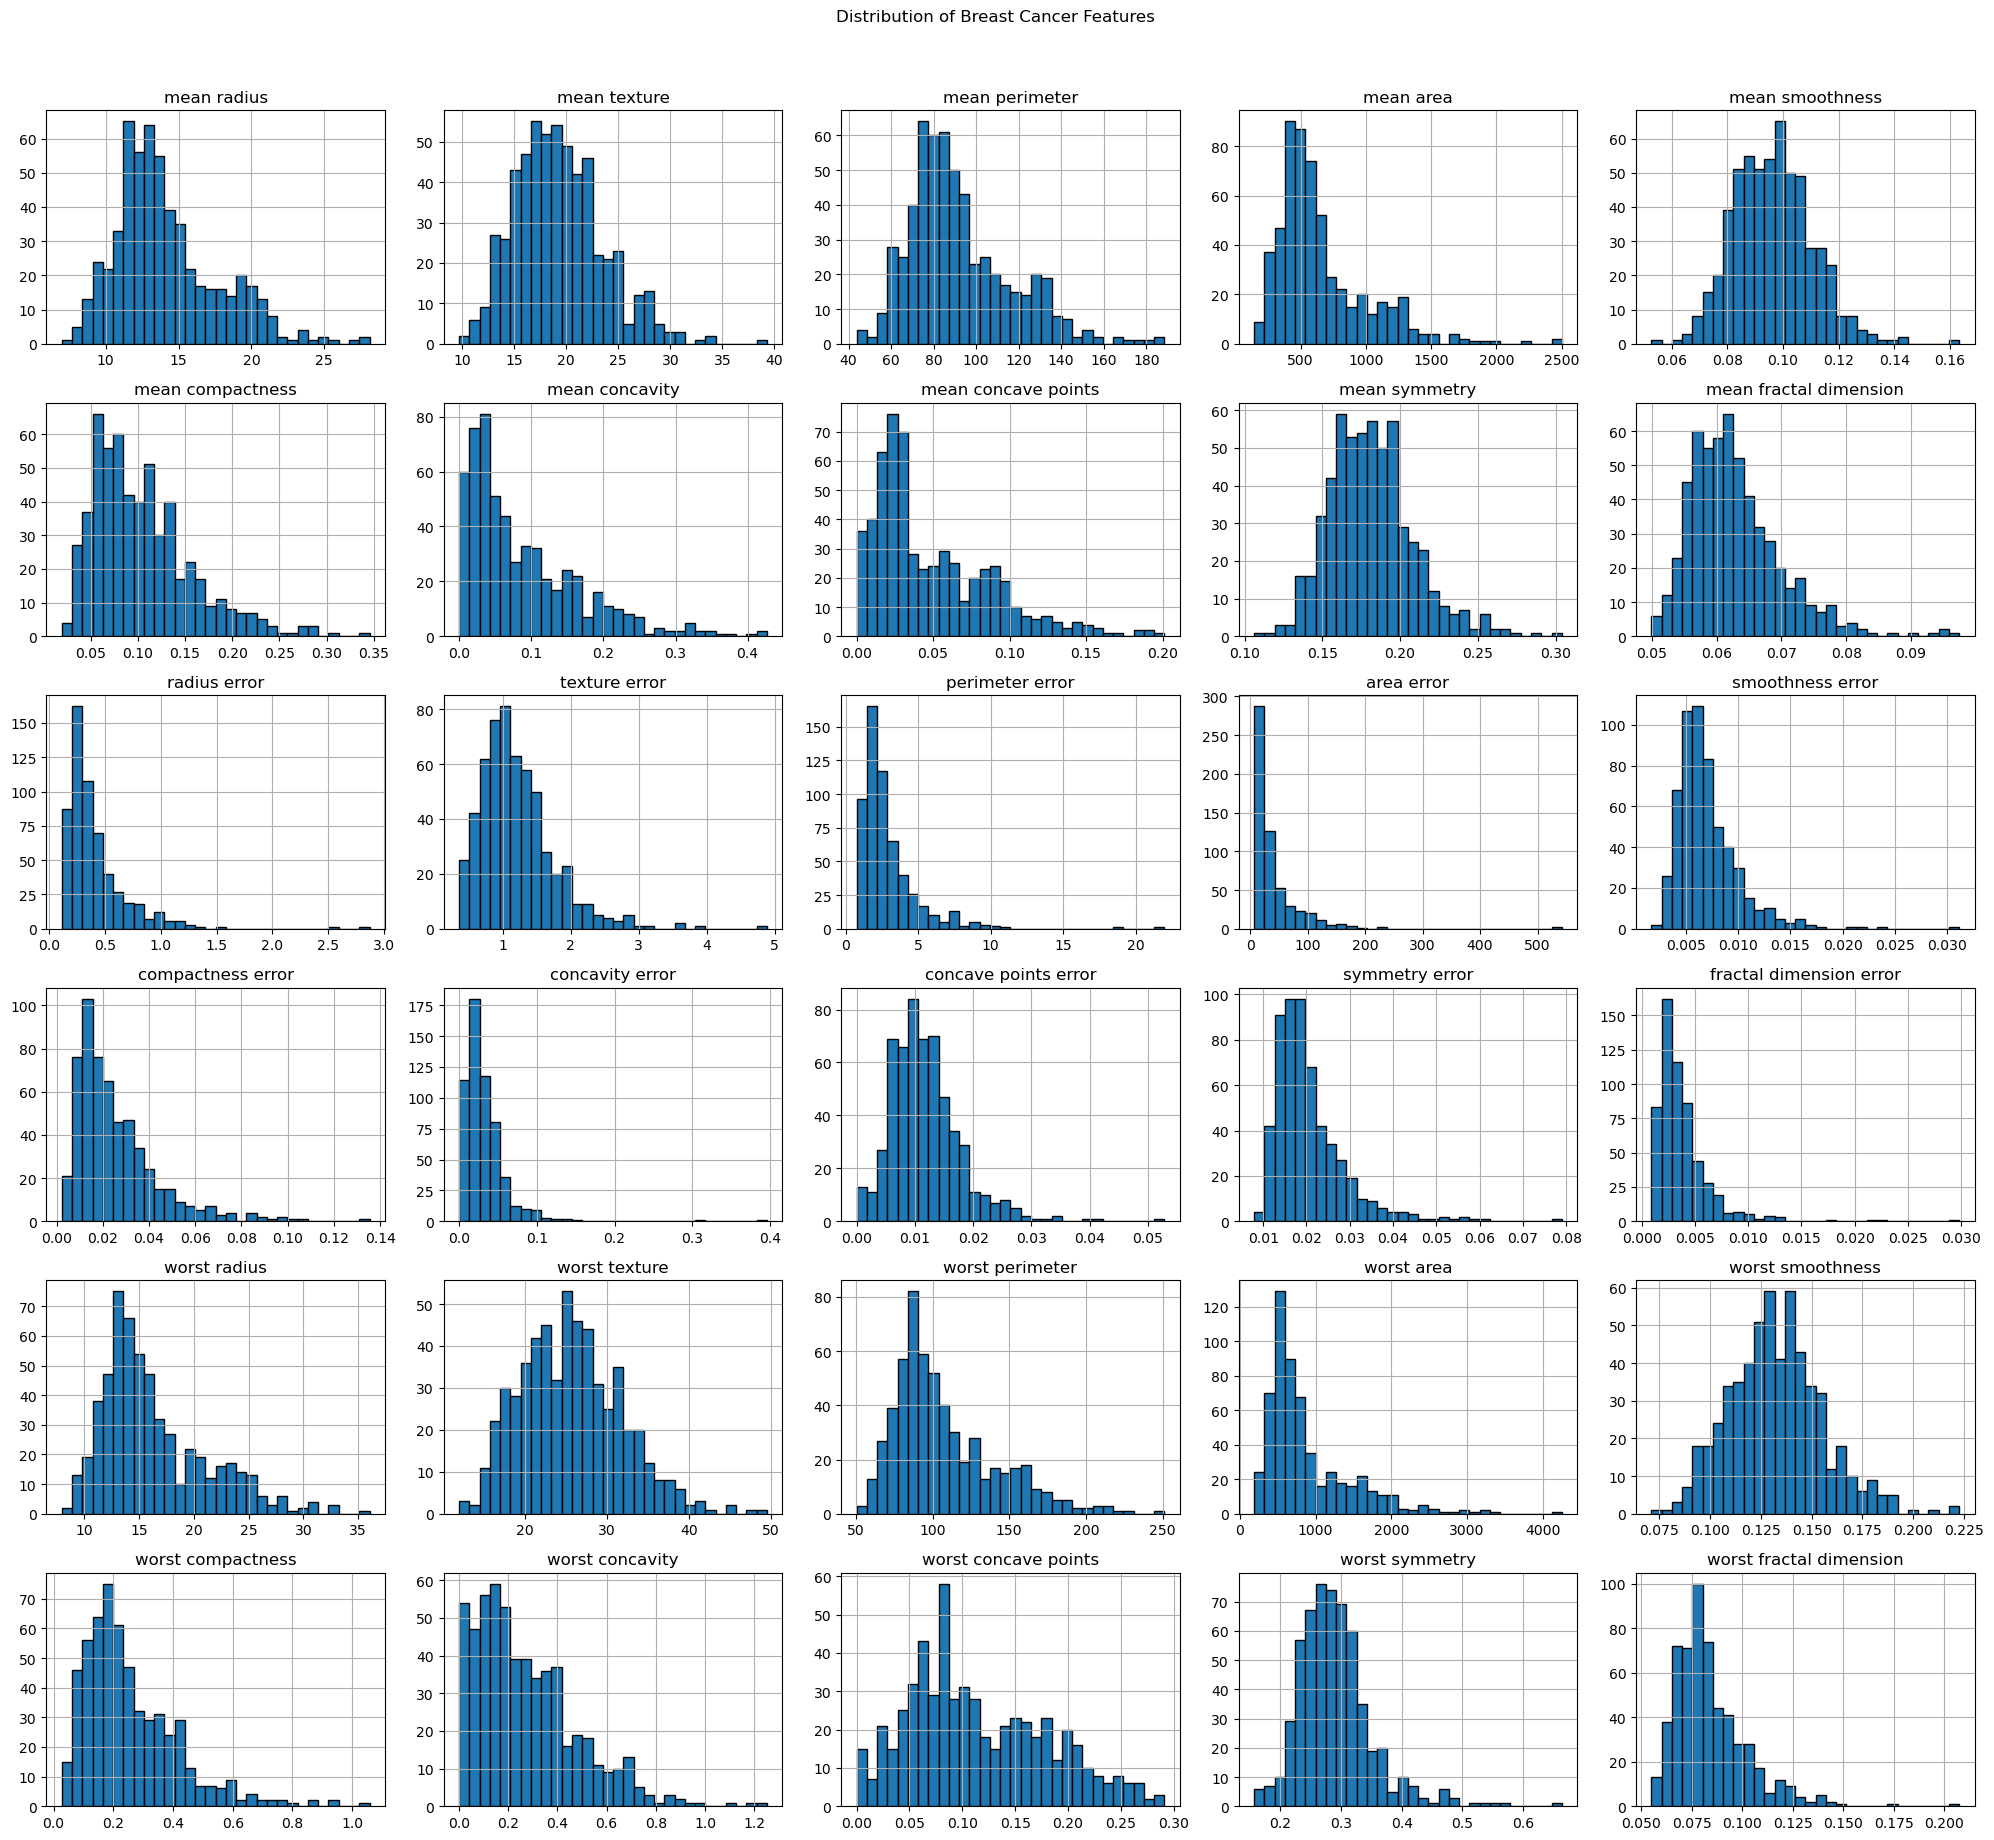

In [12]:
# feature distributions
df.drop(columns='target').hist(figsize=(20, 18),bins=30,edgecolor='black')

plt.suptitle('Distribution of Breast Cancer Features', y=1.02)
plt.tight_layout()
plt.show()

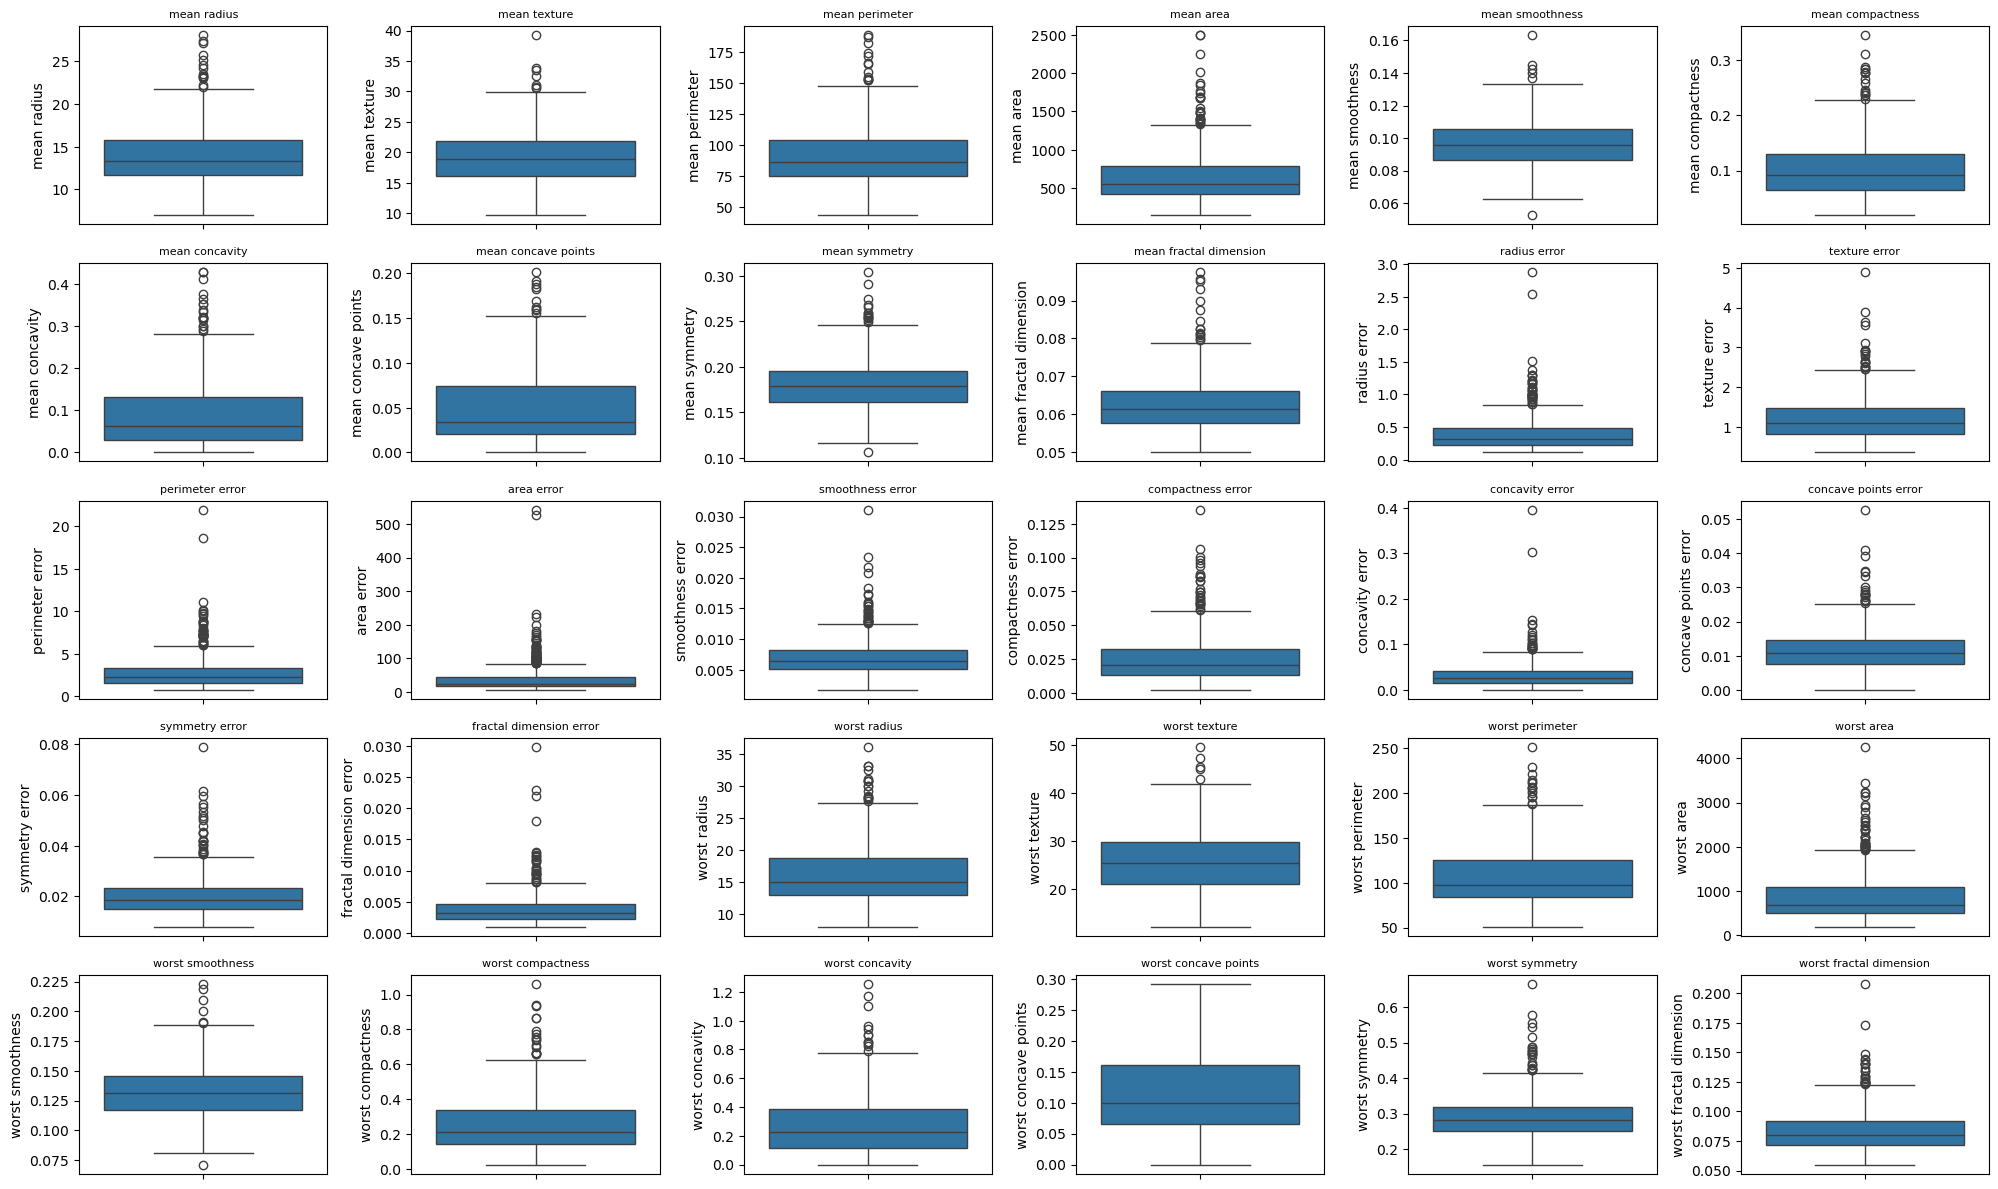

In [13]:
# outlier 
plt.figure(figsize=(20, 12))

for i, column in enumerate(df.drop(columns='target').columns, 1):
    plt.subplot(5, 6, i)
    sns.boxplot(y=df[column])
    plt.title(column, fontsize=8)

plt.tight_layout()
plt.show()

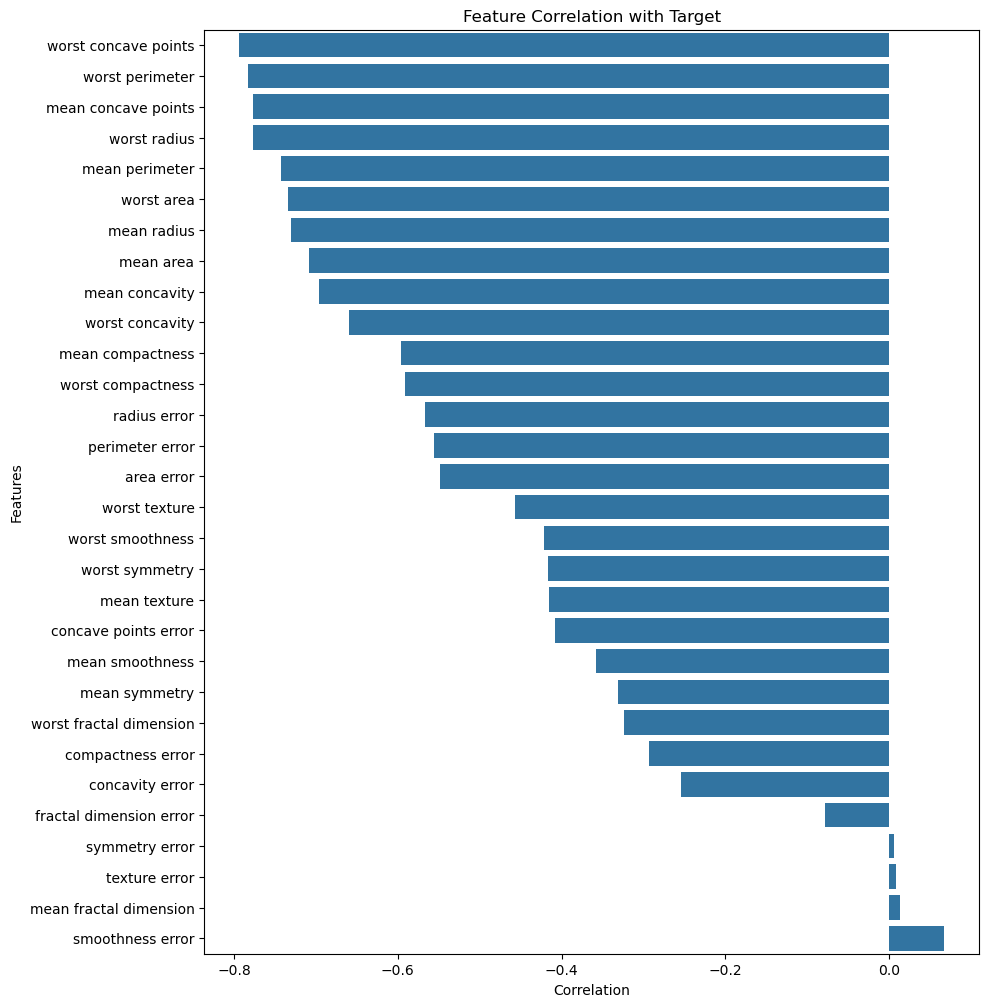

In [14]:
# feature correlation with target
target_corr = df.corr()['target'].drop('target').sort_values()

plt.figure(figsize=(10, 12))
sns.barplot(x=target_corr.values, y=target_corr.index)
plt.title('Feature Correlation with Target')
plt.xlabel('Correlation')
plt.ylabel('Features')
plt.show()

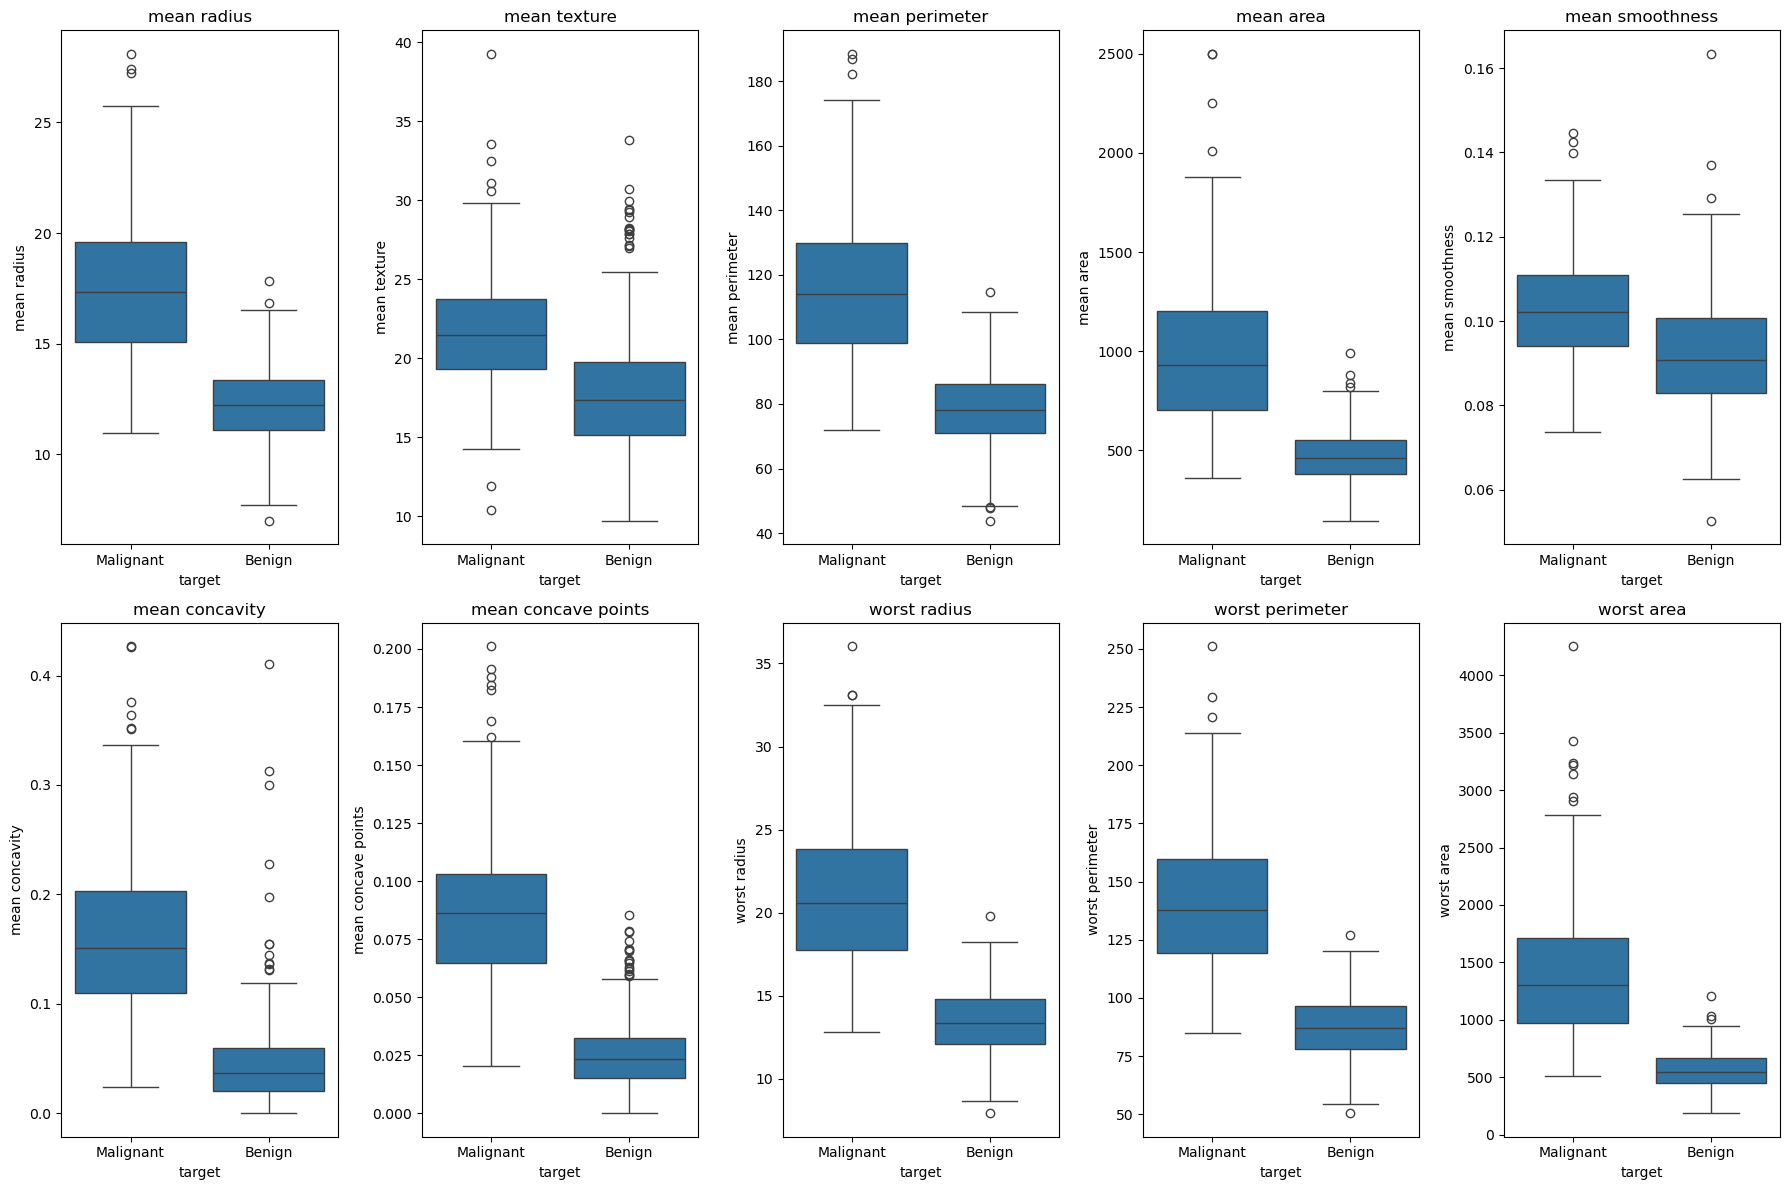

In [15]:
# Feature Relationships by Diagnosis
selected_features = [
    'mean radius',
    'mean texture',
    'mean perimeter',
    'mean area',
    'mean smoothness',
    'mean concavity',
    'mean concave points',
    'worst radius',
    'worst perimeter',
    'worst area'
]

plt.figure(figsize=(18, 12))

for i, column in enumerate(selected_features, 1):
    plt.subplot(2, 5, i)
    sns.boxplot(data=df, x='target', y=column)
    plt.title(column)
    plt.xticks([0, 1], ['Malignant', 'Benign'])

plt.tight_layout()
plt.show()

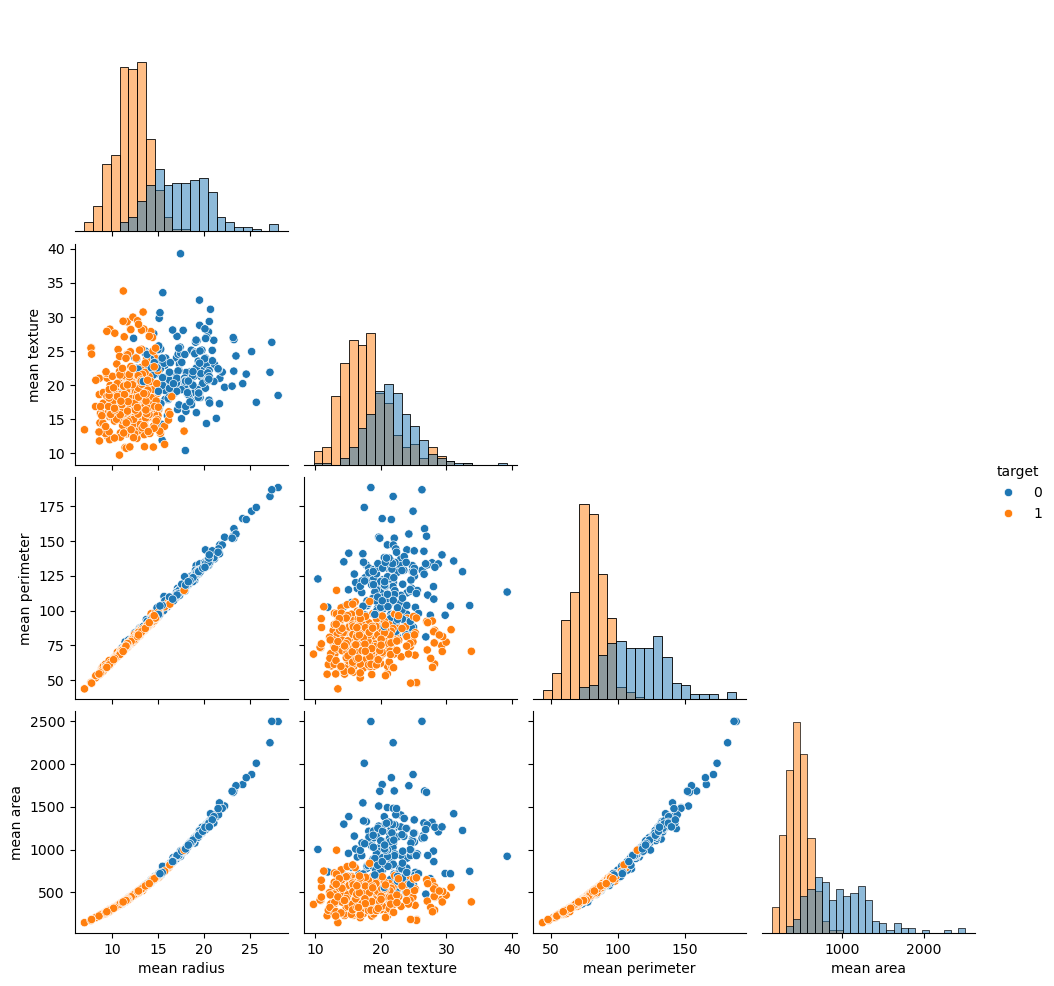

In [16]:
# Selected Features
pairplot_features = [
    'mean radius',
    'mean texture',
    'mean perimeter',
    'mean area',
    'target'
]
sns.pairplot(df[pairplot_features],hue='target',diag_kind='hist',corner=True)
plt.show()

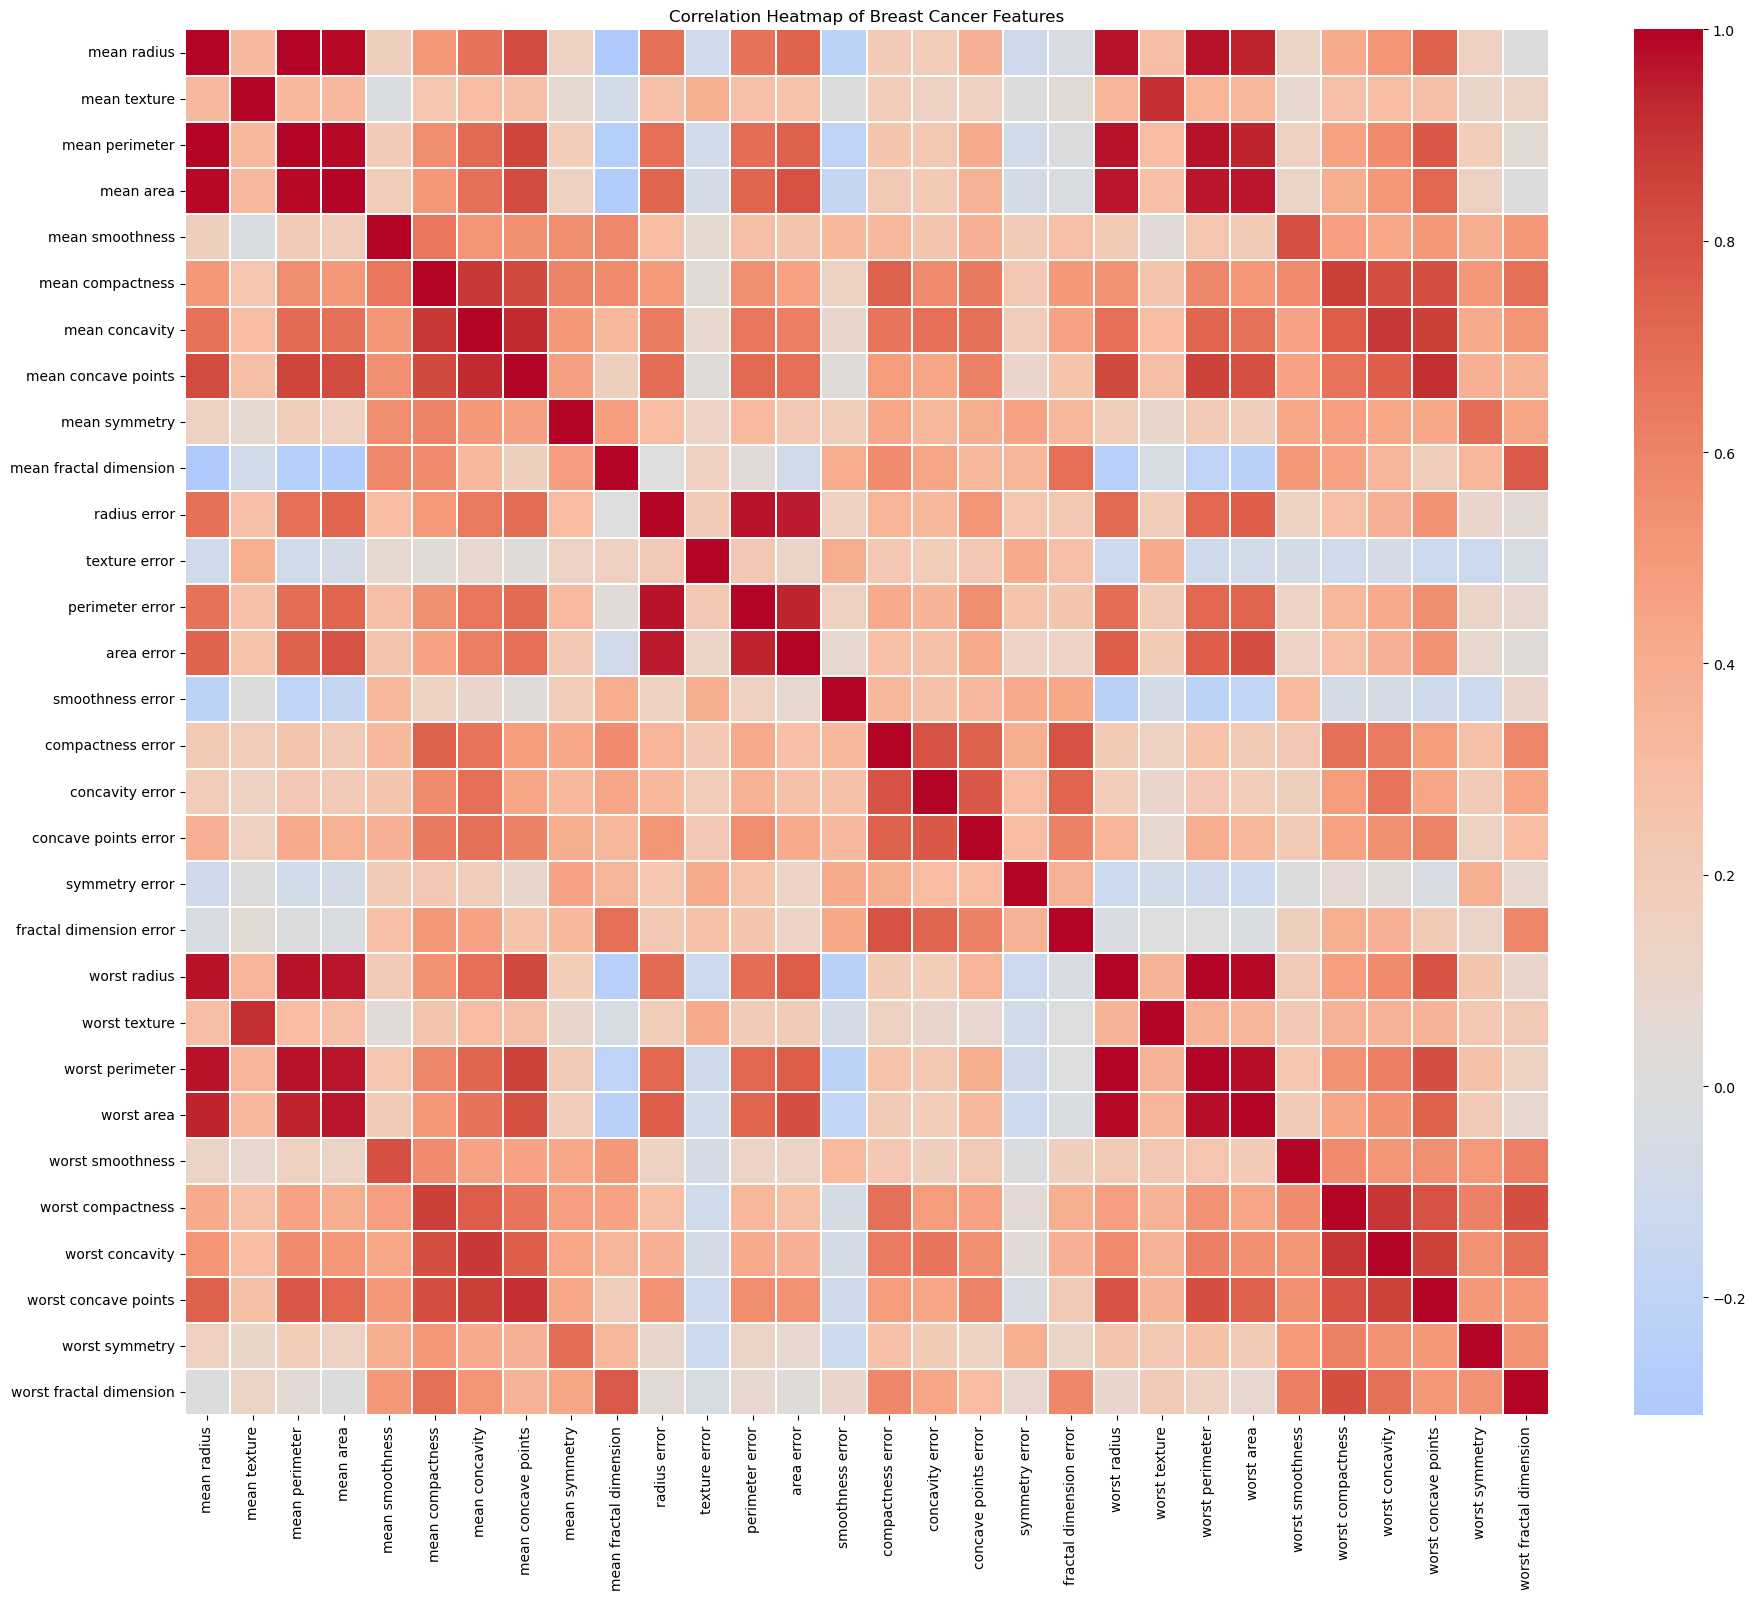

In [17]:
# correlation analysis
plt.figure(figsize=(22, 18))
correlation = df.drop(columns='target').corr()

sns.heatmap(correlation,cmap='coolwarm',center=0,linewidths=0.3)

plt.title('Correlation Heatmap of Breast Cancer Features')
plt.show()

In [18]:
# separate features and target
X = df.drop(columns='target')
y = df['target']

In [20]:
# split-train dataset
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print(X_train.shape)
X_test.shape

(455, 30)


(114, 30)

In [21]:
y_train.value_counts()

target
1    285
0    170
Name: count, dtype: int64

In [22]:
y_test.value_counts()

target
1    72
0    42
Name: count, dtype: int64

In [23]:
# Modelling
log = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=10000))
])

In [24]:
# train model
log.fit(X_train, y_train)

,steps,"[('scaler', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0


In [26]:
# predictions
y_train_pred = log.predict(X_train)
y_test_pred = log.predict(X_test)

In [28]:
# predict probabilities
y_test_proba = log.predict_proba(X_test)[:, 1]

In [29]:
# Evaluation
results = {
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC'],
    'Score': [
        accuracy_score(y_test, y_test_pred),
        precision_score(y_test, y_test_pred),
        recall_score(y_test, y_test_pred),
        f1_score(y_test, y_test_pred),
        roc_auc_score(y_test, y_test_proba)
    ]
}

evaluation = pd.DataFrame(results)
evaluation

,Metric,Score
0,Accuracy,0.982456
1,Precision,0.986111
2,Recall,0.986111
3,F1 Score,0.986111
4,ROC-AUC,0.995370


In [30]:
# classification report
print(classification_report(y_test,y_test_pred,target_names=['Malignant', 'Benign']))

              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



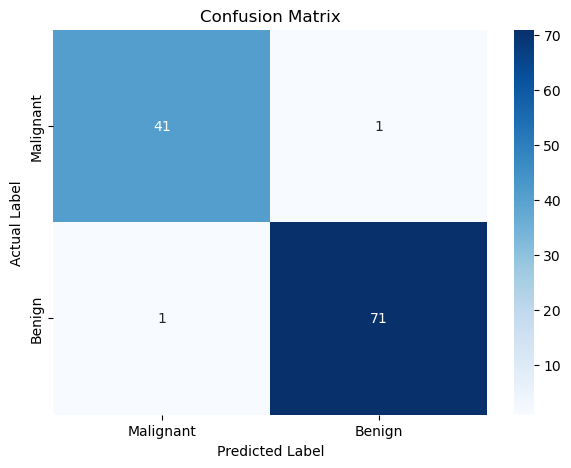

In [31]:
# confusion matrix
cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=['Malignant', 'Benign'],yticklabels=['Malignant', 'Benign'])
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix')
plt.show()

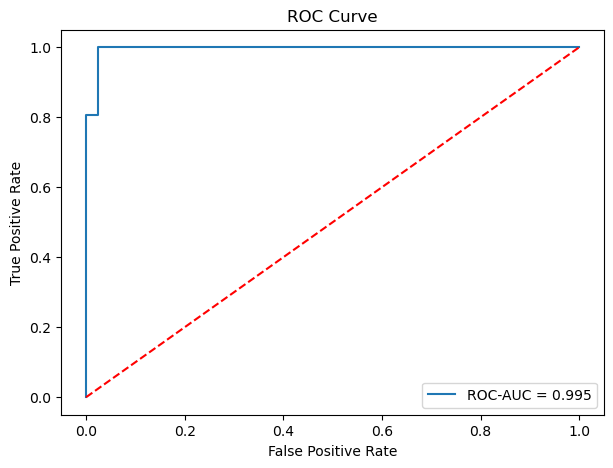

In [32]:
# ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_test_proba)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f'ROC-AUC = {roc_auc_score(y_test, y_test_proba):.3f}')
plt.plot([0, 1], [0, 1], linestyle='--', color='red')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

In [33]:
# Malignant-Class Recall
malignant_recall = recall_score(y_test,y_test_pred,pos_label=0)

print(f"Malignant Recall: {malignant_recall:.4f}")

Malignant Recall: 0.9762


#### Evaluation Interpretation

The Logistic Regression model achieved an accuracy of approximately 98.25%, indicating strong classification performance on the test dataset.

The precision, recall, and F1-score were approximately 98.61%, demonstrating strong performance in identifying benign cases.

The ROC-AUC score of 0.9954 indicates excellent discrimination between malignant and benign tumours across different classification thresholds.

Further examination of the confusion matrix and malignant-class recall is necessary to assess the model's ability to identify malignant cases.

#### Classification Report Interpretation

The classification report shows that the model performs well across both classes.

For malignant cases, the model achieved a recall of 98%, indicating that it correctly identified most malignant tumours.

For benign cases, it achieved a recall of 99%, demonstrating similarly strong classification performance.

The results indicate that Logistic Regression can distinguish between the two tumour classes effectively on the test dataset.

#  Galapagos Islands dataset

In [34]:
! pip install faraway

from statsmodels.stats.outliers_influence import variance_inflation_factor

# Data
from faraway.datasets import galapagos

In [35]:
# Load the data
data = galapagos.load()

# Inspect the data
print(data.head())
print(data.info())

# Define predictors and response variable
X = data[['Area', 'Elevation', 'Nearest']]  # Example predictors
y = data['Species']  # Response (binary outcome: presence/absence)

# Split data into training and testing sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

           Species   Area  Elevation  Nearest  Scruz  Adjacent
Baltra          58  25.09        346      0.6    0.6      1.84
Bartolome       31   1.24        109      0.6   26.3    572.33
Caldwell         3   0.21        114      2.8   58.7      0.78
Champion        25   0.10         46      1.9   47.4      0.18
Coamano          2   0.05         77      1.9    1.9    903.82
<class 'pandas.core.frame.DataFrame'>
Index: 30 entries, Baltra to Wolf
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Species    30 non-null     int64  
 1   Area       30 non-null     float64
 2   Elevation  30 non-null     int64  
 3   Nearest    30 non-null     float64
 4   Scruz      30 non-null     float64
 5   Adjacent   30 non-null     float64
dtypes: float64(4), int64(2)
memory usage: 1.6+ KB
None


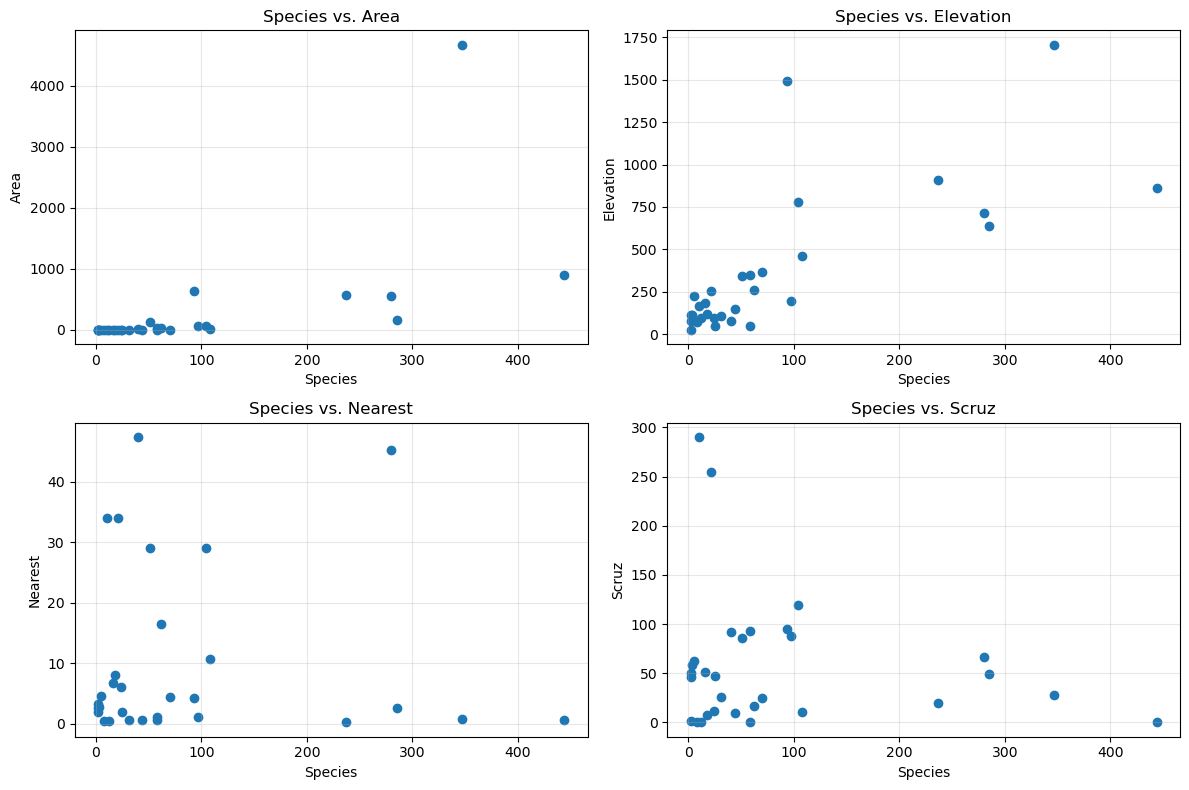

In [36]:
# Create subplots
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Plot Species vs. Area
axes[0, 0].scatter(data['Species'], data['Area'])
axes[0, 0].set_xlabel('Species')
axes[0, 0].set_ylabel('Area')
axes[0, 0].set_title('Species vs. Area')
axes[0,0].grid(alpha=0.3)

# Plot Species vs. Elevation
axes[0, 1].scatter(data['Species'], data['Elevation'])
axes[0, 1].set_xlabel('Species')
axes[0, 1].set_ylabel('Elevation')
axes[0, 1].set_title('Species vs. Elevation')
axes[0, 1].grid(alpha=0.3)


# Plot Species vs. Nearest
axes[1, 0].scatter(data['Species'], data['Nearest'])
axes[1, 0].set_xlabel('Species')
axes[1, 0].set_ylabel('Nearest')
axes[1, 0].set_title('Species vs. Nearest')
axes[1,0].grid(alpha=0.3)


# Plot Species vs. Scruz
axes[1, 1].scatter(data['Species'], data['Scruz'])
axes[1, 1].set_xlabel('Species')
axes[1, 1].set_ylabel('Scruz')
axes[1, 1].set_title('Species vs. Scruz')
axes[1,1].grid(alpha=0.3)


plt.tight_layout()  # Adjust spacing between subplots
plt.show()

In [37]:
# Define predictors and response variable
X = data[['Area', 'Elevation', 'Adjacent']]  # Example predictors

# Calculate the median of the Nearest column
median_nearest = data['Nearest'].median()

# Create the Nearest_Binary column
y= data['Nearest_Binary'] = (data['Nearest'] > median_nearest).astype(int)

# Inspect the new column
print(data[['Nearest', 'Nearest_Binary']].head(8))

              Nearest  Nearest_Binary
Baltra            0.6               0
Bartolome         0.6               0
Caldwell          2.8               0
Champion          1.9               0
Coamano           1.9               0
Daphne.Major      8.0               1
Daphne.Minor      6.0               1
Darwin           34.1               1


In [38]:
# Count the occurrences of 0 and 1
binary_counts = y.value_counts()

# Print the counts
print("Counts of 0 and 1 in Species_Binary:")
print(binary_counts)

Counts of 0 and 1 in Species_Binary:
Nearest
0    15
1    15
Name: count, dtype: int64


In [39]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


print("X_train dimensions:", X_train.shape)
print("X_test dimensions:", X_test.shape)
print("y_train dimensions:", y_train.shape)
print("y_test dimensions:", y_test.shape)

X_train dimensions: (24, 3)
X_test dimensions: (6, 3)
y_train dimensions: (24,)
y_test dimensions: (6,)


In [40]:
# Scale the predictors
scaler = StandardScaler()

# Transform training and testing predictors
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

# Get dimensions
print("Dimensions of X_train_scaled:", X_train_scaled.shape)
print("Dimensions of X_test_scaled:", X_test_scaled.shape)

Dimensions of X_train_scaled: (24, 3)
Dimensions of X_test_scaled: (6, 3)


In [41]:
# Fit logistic regression model on scaled data
model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)

# Output coefficients
print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)

Intercept: [0.36853881]
Coefficients: [[-0.54318024  0.75656123  0.05697516]]


In [42]:
# Predict probabilities and classes
y_pred_prob = model.predict_proba(X_test_scaled)[:, 1]
y_pred_class = model.predict(X_test_scaled)

# Display predictions
print("Predicted Probabilities:", y_pred_prob[:5])
print("Predicted Classes:", y_pred_class[:5])

Predicted Probabilities: [0.54407974 0.00074678 0.63293308 0.4764621  0.50250907]
Predicted Classes: [1 0 1 0 1]


In [43]:
# Evaluate model performance
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_class))
print("Accuracy Score:", accuracy_score(y_test, y_pred_class))
print("Classification Report:\n", classification_report(y_test, y_pred_class))

Confusion Matrix:
 [[1 4]
 [1 0]]
Accuracy Score: 0.16666666666666666
Classification Report:
               precision    recall  f1-score   support

           0       0.50      0.20      0.29         5
           1       0.00      0.00      0.00         1

    accuracy                           0.17         6
   macro avg       0.25      0.10      0.14         6
weighted avg       0.42      0.17      0.24         6



In [44]:
# Check multicollinearity using VIF
vif = pd.DataFrame()
vif["Variable"] = X_train.columns
vif["VIF"] = [variance_inflation_factor(X_train_scaled.values, i) for i in range(X_train_scaled.shape[1])]
print(vif)

    Variable       VIF
0       Area  2.814390
1  Elevation  4.149119
2   Adjacent  1.891136


The VIF results suggest that the independent variables do not suffer from severe multicollinearity. Therefore, all three variables can be retained for modelling based on this diagnostic

#### Summary 

The classification model achieved an accuracy of 17% on the Galápagos Islands dataset, indicating poor classification performance.

The confusion matrix shows that the model correctly classified only 1 out of 6 observations, while 5 observations were incorrectly classified.

Class 0 achieved a precision of 0.50 and a recall of 0.20, while class 1 had a precision and recall of 0.00. This indicates that the model struggled to identify both classes, particularly class 1.

The macro F1-score of 0.14 further demonstrates weak overall classification performance.

Overall, the results suggest that the model did not learn the class patterns effectively. However, the test set contains only 6 observations, which is too small to provide a reliable assessment of generalisation performance. Further investigation of the dataset, class distribution, preprocessing and model suitability is necessary.